# Assignment 2

Executed versions of `data_preparation.py`, `performance_comparison.py`, and `model.py`. Run this notebook from the Assignment2 folder with `../octmnist.npz` available. Each script cell sets `__file__` so its existing paths work in a notebook.

## Data preparation

Source: `data_preparation.py`

In [1]:
from pathlib import Path
__file__ = str(Path.cwd() / 'data_preparation.py')

import numpy as np
from collections import Counter
from pathlib import Path
from skimage import filters, exposure, util


def stratified_split(features, labels, test_fraction=0.2, seed=42):
    rng = np.random.default_rng(seed)
    train_indices, test_indices = [], []
    for class_id in np.unique(labels):
        indices = rng.permutation(np.flatnonzero(labels == class_id))
        n_test = round(len(indices) * test_fraction)
        test_indices.extend(indices[:n_test])
        train_indices.extend(indices[n_test:])
    train_indices = rng.permutation(train_indices)
    test_indices = rng.permutation(test_indices)
    return (features[train_indices], features[test_indices],
            labels[train_indices], labels[test_indices])


folder = Path(__file__).resolve().parent
data = np.load(folder.parent / "octmnist.npz")

features = []
labels = []

for split in ["train", "val", "test"]:
    for image, label in zip(data[f"{split}_images"], data[f"{split}_labels"].flatten()):
        gray = util.img_as_float(image)
        angles = np.mod(
            np.arctan2(filters.sobel_v(gray), filters.sobel_h(gray)),
            np.pi
        )
        hist, _ = exposure.histogram(angles, nbins=36)

        features.append(hist)
        labels.append(label)

features = np.array(features)
labels = np.array(labels)
train_features, test_features, train_labels, test_labels = stratified_split(features, labels)
train_mean = train_features.mean(axis=0)
train_std = train_features.std(axis=0)
train_std[train_std == 0] = 1
train_features = (train_features - train_mean) / train_std
test_features = (test_features - train_mean) / train_std

np.savez_compressed(folder / "octmnist_edge_histograms_36.npz",
                    train_features=train_features, train_labels=train_labels,
                    test_features=test_features, test_labels=test_labels,
                    train_mean=train_mean, train_std=train_std)

print("Number of images:", len(labels))
print("Number of classes:", len(np.unique(labels)))
print("Images per class:", dict(sorted(Counter(map(int, labels)).items())))
print("Feature dimensionality:", features.shape[1])
print("Training images:", len(train_labels))
print("Test images:", len(test_labels))
print("Training images per class:", dict(sorted(Counter(map(int, train_labels)).items())))
print("Test images per class:", dict(sorted(Counter(map(int, test_labels)).items())))



#question e:
#Because standardize test with training data, will make the test result looks better than on unseen images.


Number of images: 109309
Number of classes: 4
Images per class: {0: 37455, 1: 11598, 2: 8866, 3: 51390}
Feature dimensionality: 36
Training images: 87447
Test images: 21862
Training images per class: {0: 29964, 1: 9278, 2: 7093, 3: 41112}
Test images per class: {0: 7491, 1: 2320, 2: 1773, 3: 10278}


## Performance comparison

Source: `performance_comparison.py`

In [2]:
from pathlib import Path
__file__ = str(Path.cwd() / 'performance_comparison.py')

from pathlib import Path
import subprocess
import sys

import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
import numpy as np
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import ConfusionMatrixDisplay, accuracy_score, f1_score
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.naive_bayes import GaussianNB
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier


folder = Path(__file__).resolve().parent
feature_file = folder / "octmnist_edge_histograms_36.npz"
if not feature_file.exists():
    subprocess.run([sys.executable, str(folder / "data_preparation.py")], check=True)

with np.load(feature_file) as data:
    train_features = data["train_features"]
    train_labels = data["train_labels"]
    test_features = data["test_features"]
    test_labels = data["test_labels"]

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
np.random.seed(42)
classifiers = [
    ("GaussianNB", GaussianNB(), "gaussian_nb"),
    ("DecisionTreeClassifier(max_depth=10)", DecisionTreeClassifier(max_depth=10), "decision_tree"),
    ("RandomForestClassifier", RandomForestClassifier(), "random_forest"),
]

print("| Classifier | Mean Validation Accuracy | Standard Deviation |", flush=True)
print("|---|---:|---:|", flush=True)
for name, classifier, _ in classifiers:
    # Refit scaling inside each fold, using only that fold's training portion.
    model = make_pipeline(StandardScaler(), classifier)
    scores = cross_val_score(model, train_features, train_labels, cv=cv, scoring="accuracy")
    print(f"| {name} | {scores.mean():.4f} | {scores.std():.4f} |", flush=True)

 #question 2: Random Forest. It had the highest mean validation accuracy and the lowest standard deviation   

class_names = [
    "CNV\n(choroidal neovascularization)",
    "DME\n(diabetic macular edema)",
    "Drusen",
    "Normal",
]

print("\n| Classifier | Test Accuracy | Macro F1-score |", flush=True)
print("|---|---:|---:|", flush=True)
for name, classifier, filename in classifiers:
    model = make_pipeline(StandardScaler(), classifier)
    model.fit(train_features, train_labels)
    predictions = model.predict(test_features)
    accuracy = accuracy_score(test_labels, predictions)
    macro_f1 = f1_score(test_labels, predictions, average="macro")
    print(f"| {name} | {accuracy:.4f} | {macro_f1:.4f} |", flush=True)

    fig, ax = plt.subplots(figsize=(10, 8))
    ConfusionMatrixDisplay.from_predictions(
        test_labels, predictions,
        labels=[0, 1, 2, 3], display_labels=class_names,
        cmap="Blues", values_format="d", colorbar=False,
        xticks_rotation=25, ax=ax,
    )
    ax.set_title(f"{name} — held-out test set")
    fig.tight_layout()
    fig.savefig(folder / f"{filename}_confusion_matrix.png", dpi=180)
    plt.close(fig)

#question d: CNV and normal.
#CNV can distort layers locally, but at 28×28 resolution, the difference is less distinct. 
#The 36-bin histogram counts edge directions while discarding where the edges occur, so it can give similar vectors.

#question e:  Left: true class CNV; predicted normal.  Right: true class normal; predicted CNV.
#Yes. The CNV image on the left has smooth, horizontal bright bands, so it resembles a normal scan. 
#The normal image on the right has a sloping, uneven bright band that could resemble the distortion seen in some CNV scans.
#At 28×28 pixels, those details are hard to distinguish.

| Classifier | Mean Validation Accuracy | Standard Deviation |


|---|---:|---:|


| GaussianNB | 0.5936 | 0.0039 |


| DecisionTreeClassifier(max_depth=10) | 0.6331 | 0.0044 |


| RandomForestClassifier | 0.6904 | 0.0020 |



| Classifier | Test Accuracy | Macro F1-score |


|---|---:|---:|


| GaussianNB | 0.5921 | 0.4104 |


| DecisionTreeClassifier(max_depth=10) | 0.6352 | 0.3960 |


| RandomForestClassifier | 0.6989 | 0.4858 |


### Confusion matrices

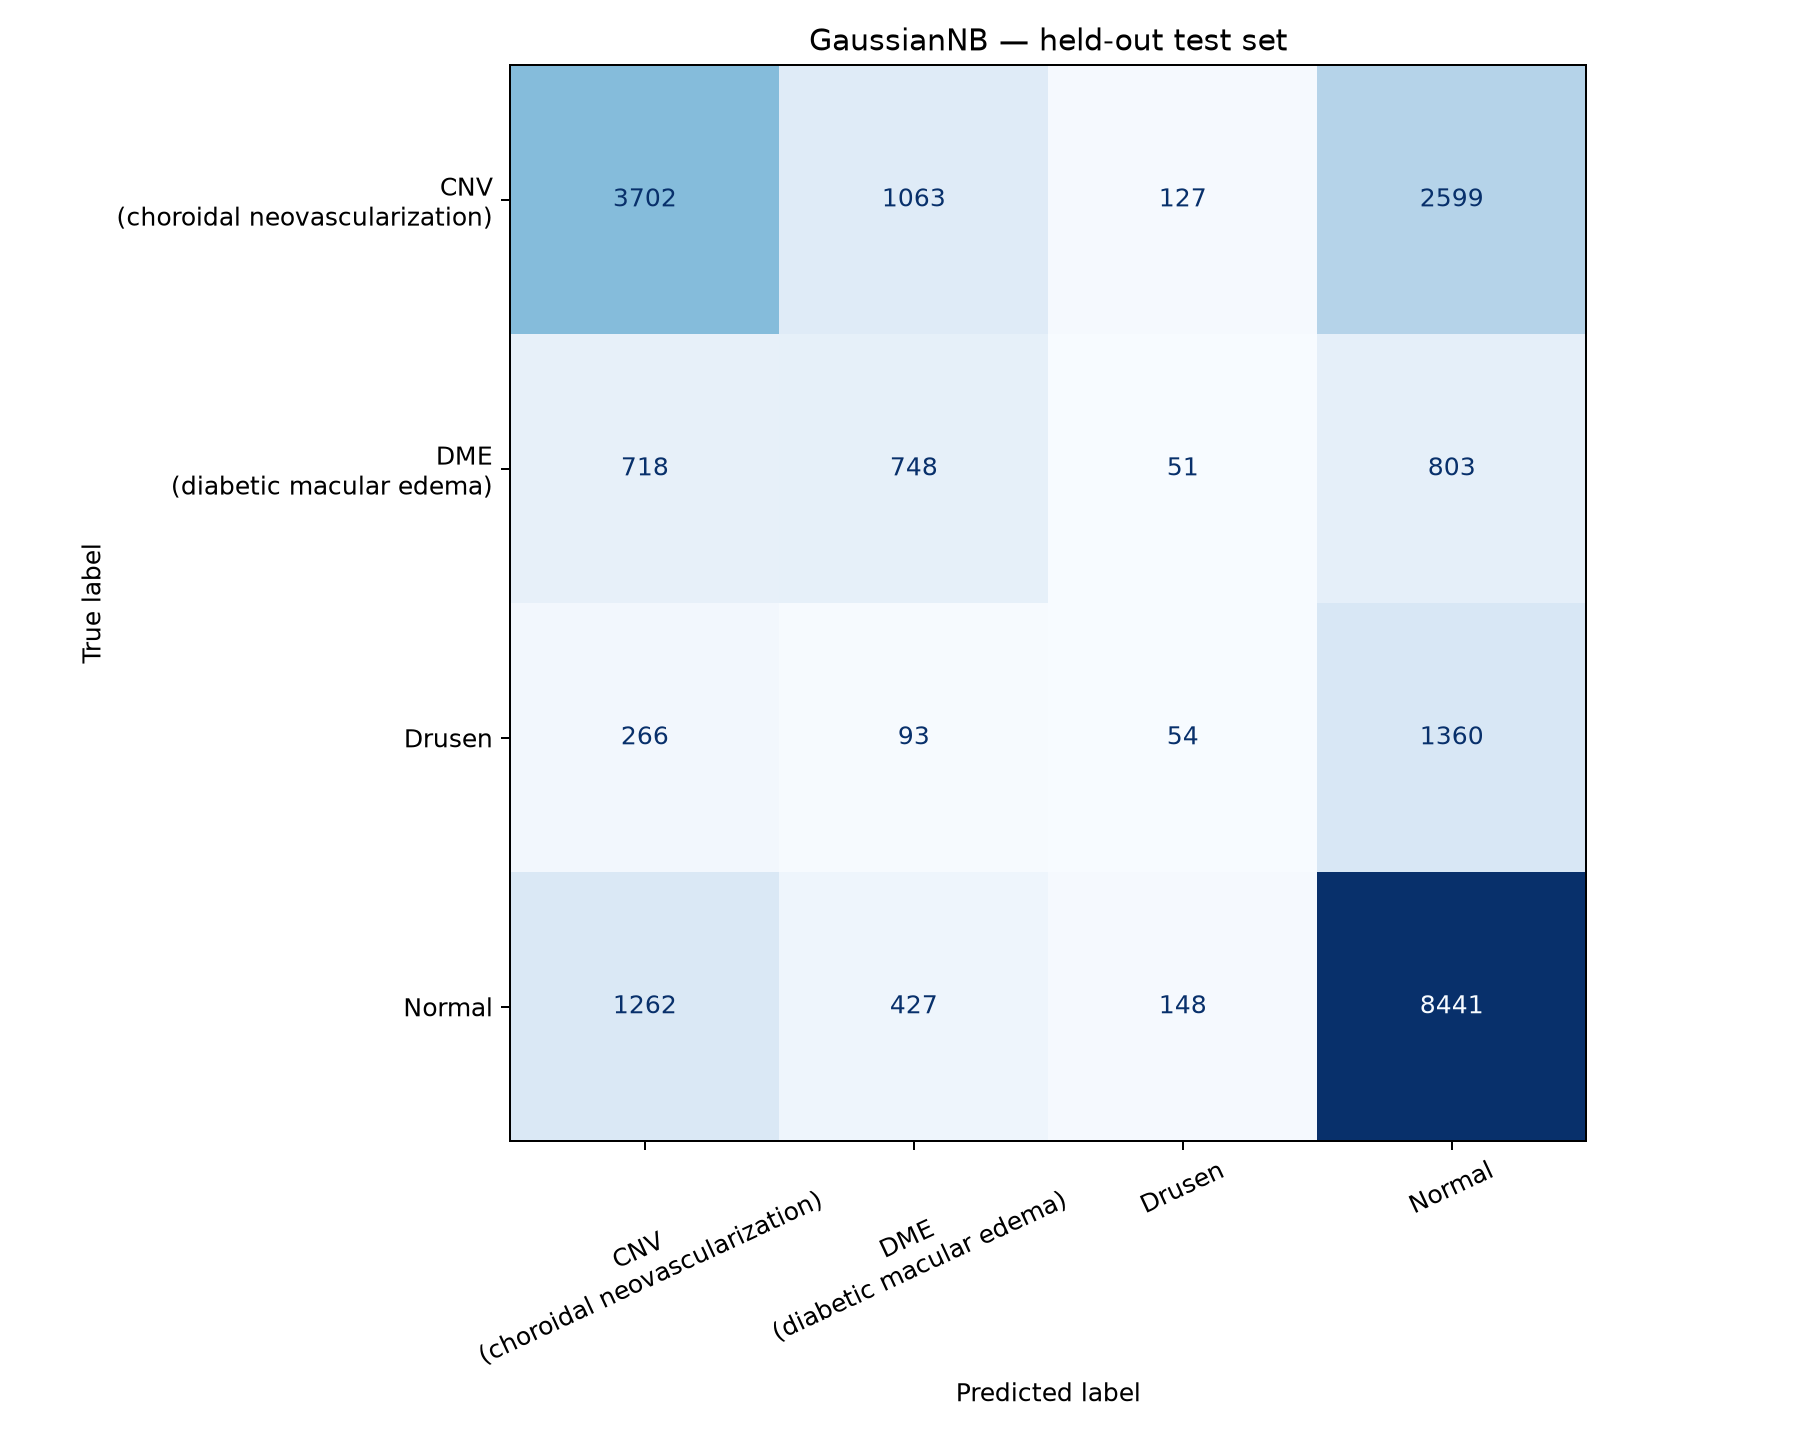

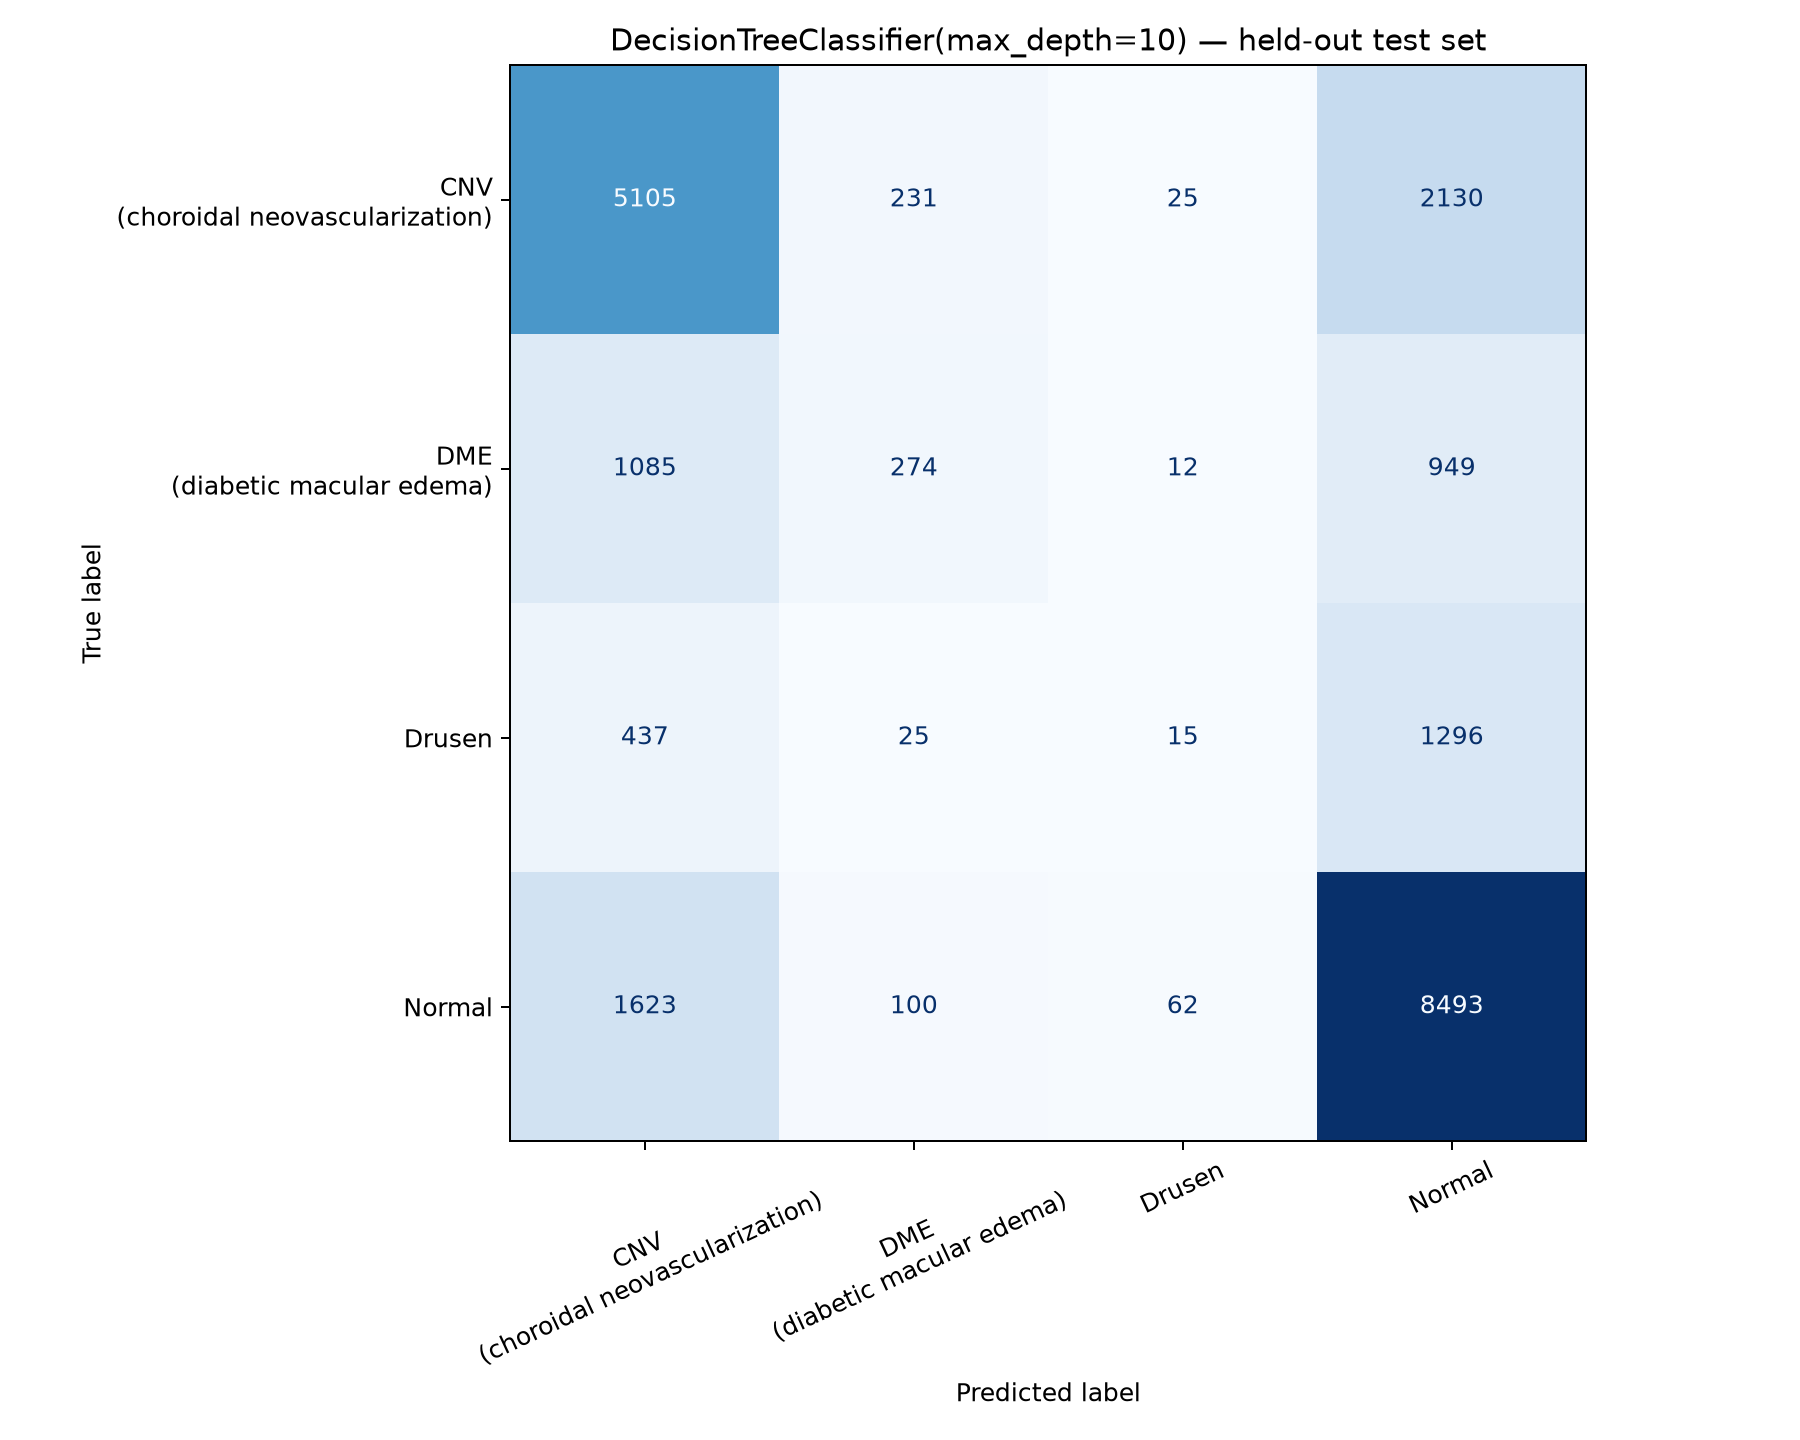

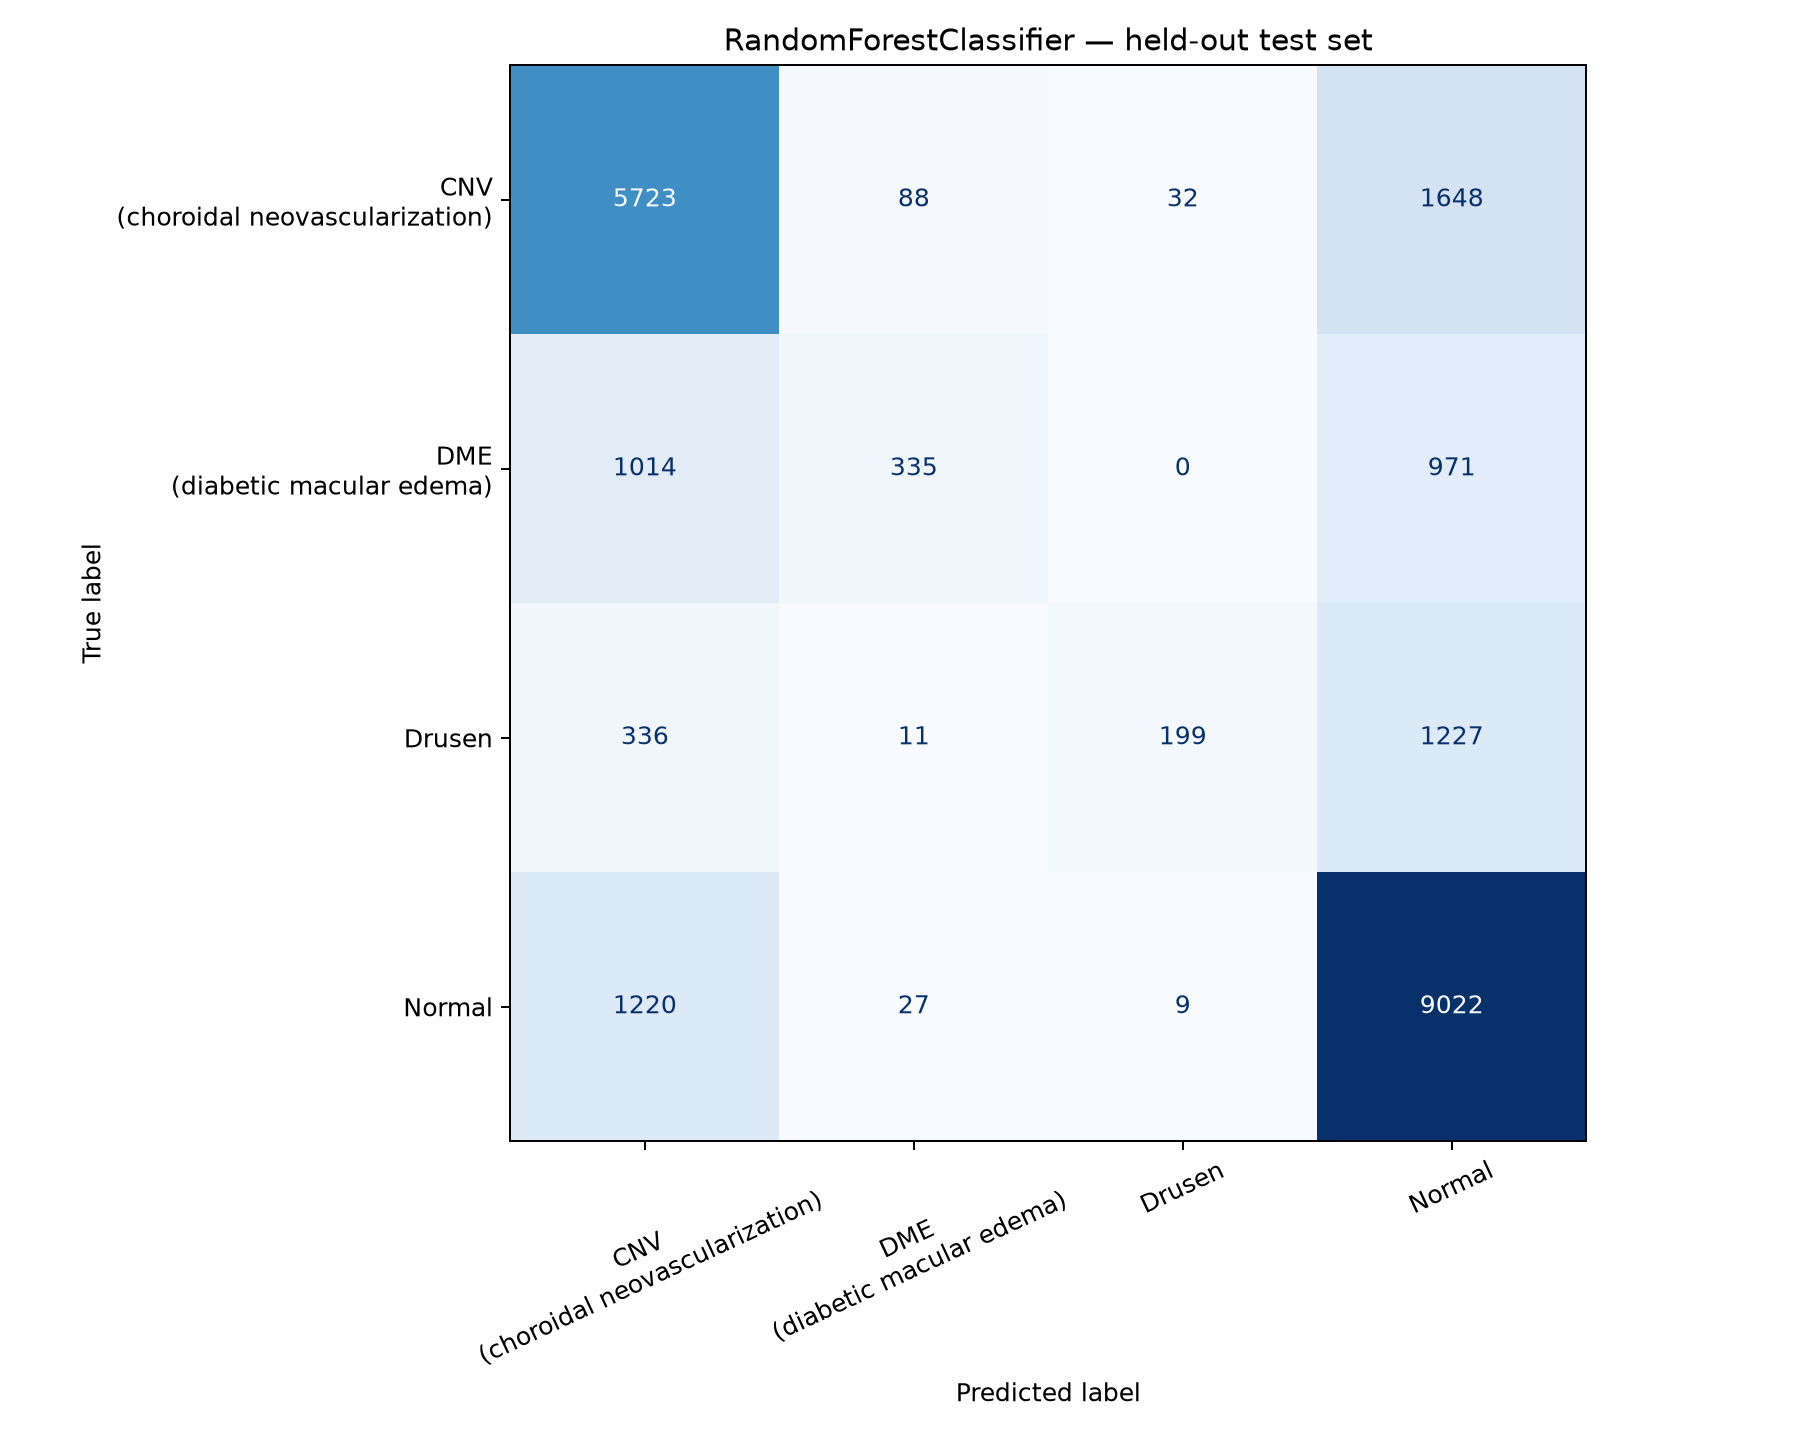

In [3]:
from IPython.display import Image, display
for filename in ('gaussian_nb_confusion_matrix.png',
                 'decision_tree_confusion_matrix.png',
                 'random_forest_confusion_matrix.png'):
    display(Image(filename=str(Path.cwd() / filename)))

## Model selection and model complexity

Source: `model.py`

In [4]:
from pathlib import Path
__file__ = str(Path.cwd() / 'model.py')

from pathlib import Path
import subprocess
import sys

import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
import numpy as np
from sklearn.model_selection import KFold, StratifiedKFold, cross_validate
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import LinearSVC


folder = Path(__file__).resolve().parent
feature_file = folder / "octmnist_edge_histograms_36.npz"
if not feature_file.exists():
    subprocess.run([sys.executable, str(folder / "data_preparation.py")], check=True)

with np.load(feature_file) as data:
    labels = data["train_labels"]
    selected = np.isin(labels, [0, 3])
    features = data["train_features"][selected]
    labels = labels[selected]
    test_labels = data["test_labels"]
    test_selected = np.isin(test_labels, [0, 3])
    test_features = data["test_features"][test_selected]
    test_labels = test_labels[test_selected]

print("Selected classes: CNV and normal", flush=True)
print(f"Training images: {len(labels)}", flush=True)

c_values = [0.01, 0.1, 1, 10, 100, 1000]
cv_methods = [
    ("Standard 5-fold CV", KFold(n_splits=5, shuffle=True, random_state=42)),
    ("Stratified 5-fold CV", StratifiedKFold(n_splits=5, shuffle=True, random_state=42)),
]
errors = {}

print("| C | Standard train error (%) | Standard validation error (%) | "
      "Stratified train error (%) | Stratified validation error (%) |", flush=True)
print("|---:|---:|---:|---:|---:|", flush=True)
for c in c_values:
    row = {}
    for method_name, cv in cv_methods:
        # Scaling is fitted separately on each fold's training portion.
        model = make_pipeline(StandardScaler(), LinearSVC(C=c))
        scores = cross_validate(
            model, features, labels, cv=cv, scoring="accuracy",
            return_train_score=True, n_jobs=5,
        )
        row[method_name] = (
            100 * (1 - scores["train_score"]).mean(),
            100 * (1 - scores["test_score"]).mean(),
        )
    errors[c] = row
    standard_train, standard_val = row["Standard 5-fold CV"]
    stratified_train, stratified_val = row["Stratified 5-fold CV"]
    print(f"| {c:g} | {standard_train:.3f} | {standard_val:.3f} | "
          f"{stratified_train:.3f} | {stratified_val:.3f} |", flush=True)

fig, ax = plt.subplots(figsize=(9, 6))
for method_name, color in (("Standard 5-fold CV", "tab:blue"),
                           ("Stratified 5-fold CV", "tab:orange")):
    train_errors = [errors[c][method_name][0] for c in c_values]
    validation_errors = [errors[c][method_name][1] for c in c_values]
    ax.plot(c_values, train_errors, marker="o", linestyle="-", color=color,
            label=f"{method_name} training error")
    ax.plot(c_values, validation_errors, marker="s", linestyle="--", color=color,
            label=f"{method_name} validation error")

ax.set_xscale("log")
ax.set_xticks(c_values)
ax.set_xticklabels([str(c) for c in c_values])
ax.set_xlabel("C")
ax.set_ylabel("Mean error (%)")
ax.set_title("LinearSVC model complexity: CNV vs normal")
ax.grid(True, alpha=0.3)
ax.legend()
fig.tight_layout()
plot_path = folder / "model_selection_complexity.png"
fig.savefig(plot_path, dpi=200)
plt.close(fig)
print(f"Saved: {plot_path}")

best_c = min(c_values, key=lambda c: errors[c]["Stratified 5-fold CV"][1])
validation_error = errors[best_c]["Stratified 5-fold CV"][1]
model = make_pipeline(StandardScaler(), LinearSVC(C=best_c))
model.fit(features, labels)
test_error = 100 * (1 - model.score(test_features, test_labels))
print(f"Selected C: {best_c:g}")
print(f"Stratified CV validation error: {validation_error:.6f}%")
print(f"Held-out test error: {test_error:.6f}%")


"""
1.C = 1, 10, 100, and 1000 tie at 21.198% at the reported precision.
2.It weakens regularization, allowing the fitted boundary to respond more closely to the training data.
3.21.13% training error and 21.18 to 21.20% validation error stay high. That is consistent with the linear model or these edge-histogram features being too limited to separate the classes well.
4.Not observed. Validation error stays only about 0.05 to 0.07 percentage points above training error, and the gap does not grow with C.
5.Very similar.Their validation errors differ by at most 0.024 percentage.
"""


Selected classes: CNV and normal


Training images: 71076


| C | Standard train error (%) | Standard validation error (%) | Stratified train error (%) | Stratified validation error (%) |


|---:|---:|---:|---:|---:|


| 0.01 | 21.137 | 21.204 | 21.133 | 21.180 |


| 0.1 | 21.137 | 21.200 | 21.131 | 21.180 |


... (3 outputs left out)

| 1000 | 21.138 | 21.198 | 21.131 | 21.180 |


Saved: /home/jaydenhu/Downloads/Program2/Assignment2/model_selection_complexity.png


Selected C: 0.1
Stratified CV validation error: 21.180149%
Held-out test error: 21.357420%


'\n1.C = 1, 10, 100, and 1000 tie at 21.198% at the reported precision.\n2.It weakens regularization, allowing the fitted boundary to respond more closely to the training data.\n3.21.13% training error and 21.18 to 21.20% validation error stay high. That is consistent with the linear model or these edge-histogram features being too limited to separate the classes well.\n4.Not observed. Validation error stays only about 0.05 to 0.07 percentage points above training error, and the gap does not grow with C.\n5.Very similar.Their validation errors differ by at most 0.024 percentage.\n'

### LinearSVC error curves

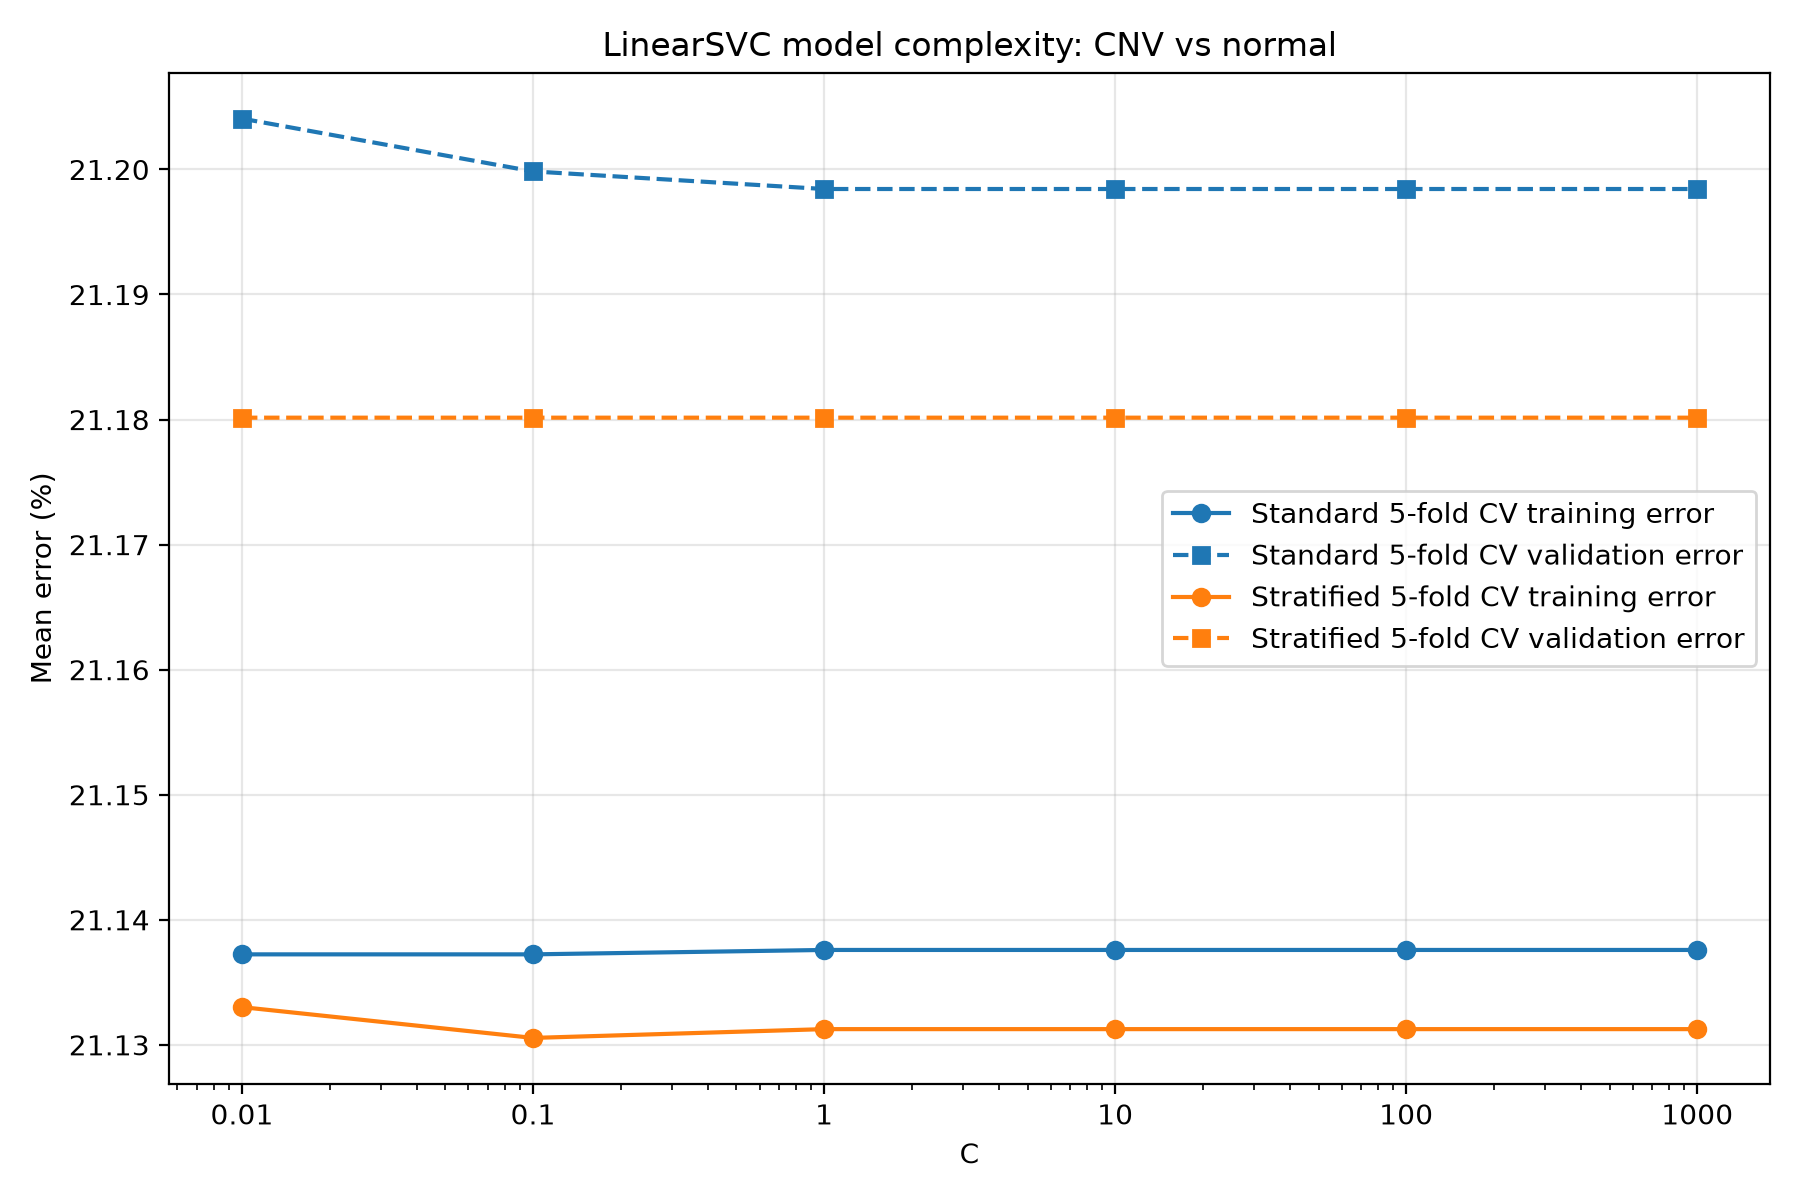

In [5]:
display(Image(filename=str(Path.cwd() / 'model_selection_complexity.png')))